In [2]:
# ## MATPLOTLIB SETTINGS
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable
mpl.rc('axes',   titlesize=20)
mpl.rc('axes',   labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, FormatStrFormatter, FixedLocator
from matplotlib.colors import ListedColormap
colors = ['#ff0000', "#41b6c4",  "olivedrab", "darkviolet", '#030764', "#000080"]
my_cmap = ListedColormap(colors, name="my_cmap")
font_dict = {'family': 'serif', 'color':  None,  'weight': 'bold','size': 30}
#############################################
from cobaya.run import run
from getdist import loadMCSamples
import getdist.plots as gdplt
from getdist import MCSamples
from getdist import plots
#############################################
#BASIC SYSTEM PACKAGES
import sys,time, os, camb, h5py, corner, emcee
from copy import deepcopy as dcopy
#############################################
#FURTHER BASIC PACKAGES
from scipy import integrate
from scipy.interpolate import interp1d
import numpy as np
from scipy.stats import chi2 as chi2_func

In [3]:
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }

In [4]:
ibin = 1
bunnin_perc = 0.0
smooth_perc = 0.7
###################################################################################################################
# 5k sims | CV model 3 |TF estimator=HUBER
burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()    
###################################################################################################################
## OLD [NEED 2run new]
#filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_bin{}__newcov__hi_error_{}_simulated.h5".format(ibin,'100')
#burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_simulated.h5".format(ibin, 3)
print( filename_cl_h5 )
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_sim = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
)      
###################################################################################################################
#burnin=100
filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_theory.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_thr = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_thr = chi2.min()    


Backend loaded. Initial number of steps: 5020 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_1bin__COVmodel3__hi_error_100__500sims_estimated.h5
/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_1bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 3302  | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_1bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 7000  | /data/AMARINS/EXTERNAL/DESKTOP/outputs/emcee_cx_cpl_1bin__COVmodel3__hi_error_100__500sims_theory.h5


/data/AMARINS/LSSxHI-CODES/images/2D_cross_set1_4paper.png


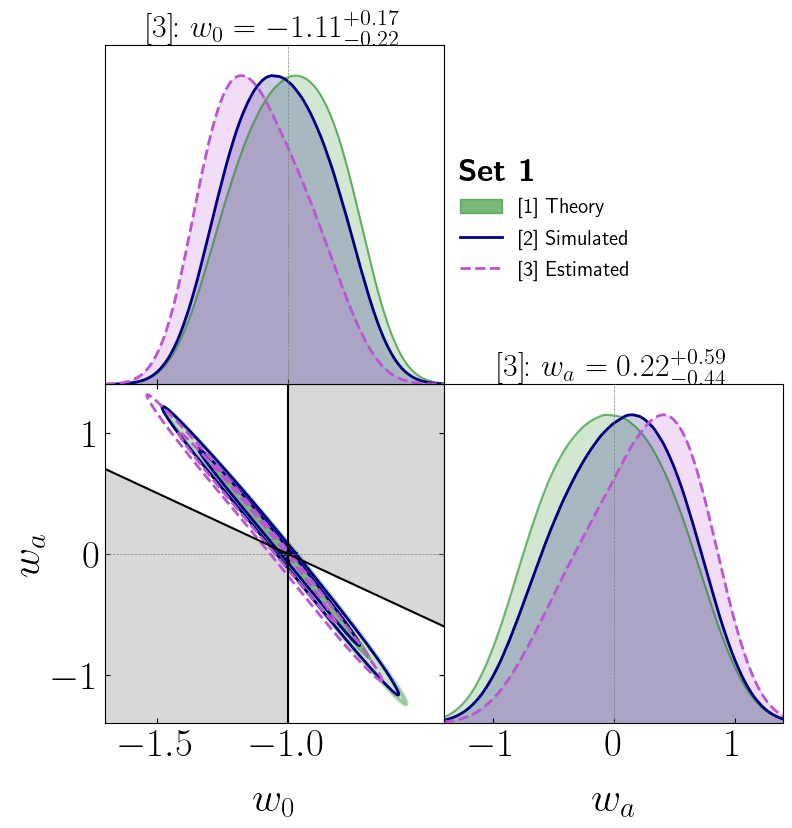

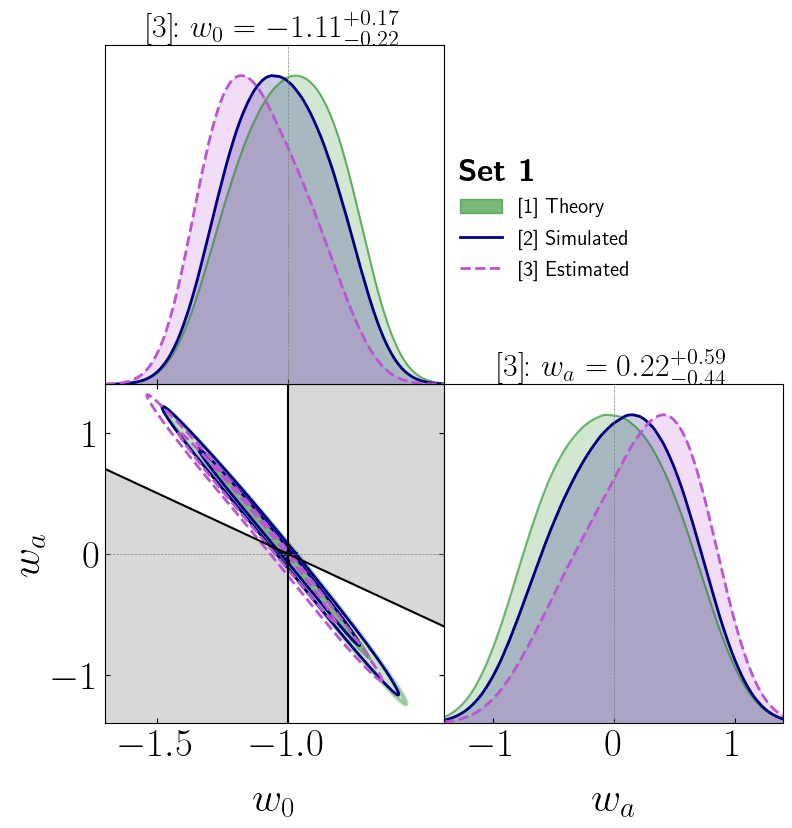

In [11]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [5]:
ibin = 2
bunnin_perc = 0.0
smooth_perc = 0.7
####################
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }
###################################################################################################################
# 5k sims | CV model 3 |TF estimator=HUBER
burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()    
###################################################################################################################
## OLD [NEED 2run new]
#filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_bin{}__newcov__hi_error_{}_simulated.h5".format(ibin,'100')
#burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_simulated.h5".format(ibin, 3)
print( filename_cl_h5 )
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_sim = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
)      
###################################################################################################################
#burnin=100
filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_theory.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_thr = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_thr = chi2.min()    


Backend loaded. Initial number of steps: 3950 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_2bin__COVmodel3__hi_error_100__500sims_estimated.h5
/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_2bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 2000  | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_2bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 7000  | /data/AMARINS/EXTERNAL/DESKTOP/outputs/emcee_cx_cpl_2bin__COVmodel3__hi_error_100__500sims_theory.h5


/data/AMARINS/LSSxHI-CODES/images/2D_cross_set2_4paper.png


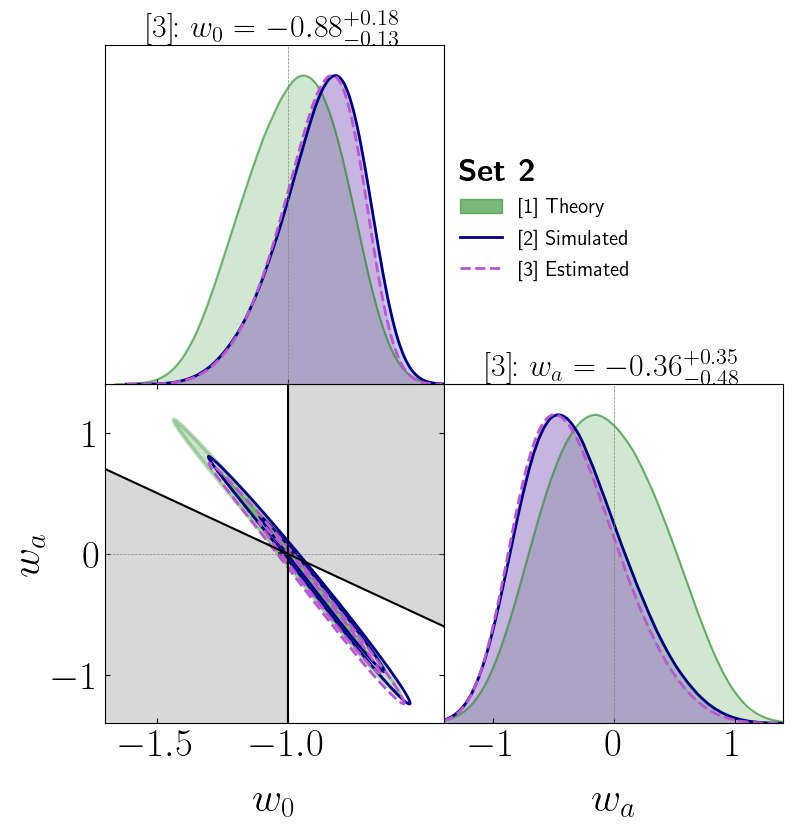

In [204]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [205]:
ibin = 3
bunnin_perc = 0.0
smooth_perc = 0.7
####################
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }
###################################################################################################################
# 5k sims | CV model 3 |TF estimator=HUBER
burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()    
###################################################################################################################
## OLD [NEED 2run new]
#filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_bin{}__newcov__hi_error_{}_simulated.h5".format(ibin,'100')
#burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_simulated.h5".format(ibin, 3)
print( filename_cl_h5 )
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_sim = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
)      
###################################################################################################################
#burnin=100
filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_theory.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_thr = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_thr = chi2.min()    


Backend loaded. Initial number of steps: 3751 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_3bin__COVmodel3__hi_error_100__500sims_estimated.h5
/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_3bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 1435  | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_3bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 3162  | /data/AMARINS/EXTERNAL/DESKTOP/outputs/emcee_cx_cpl_3bin__COVmodel3__hi_error_100__500sims_theory.h5


/data/AMARINS/LSSxHI-CODES/images/2D_cross_set3_4paper.png


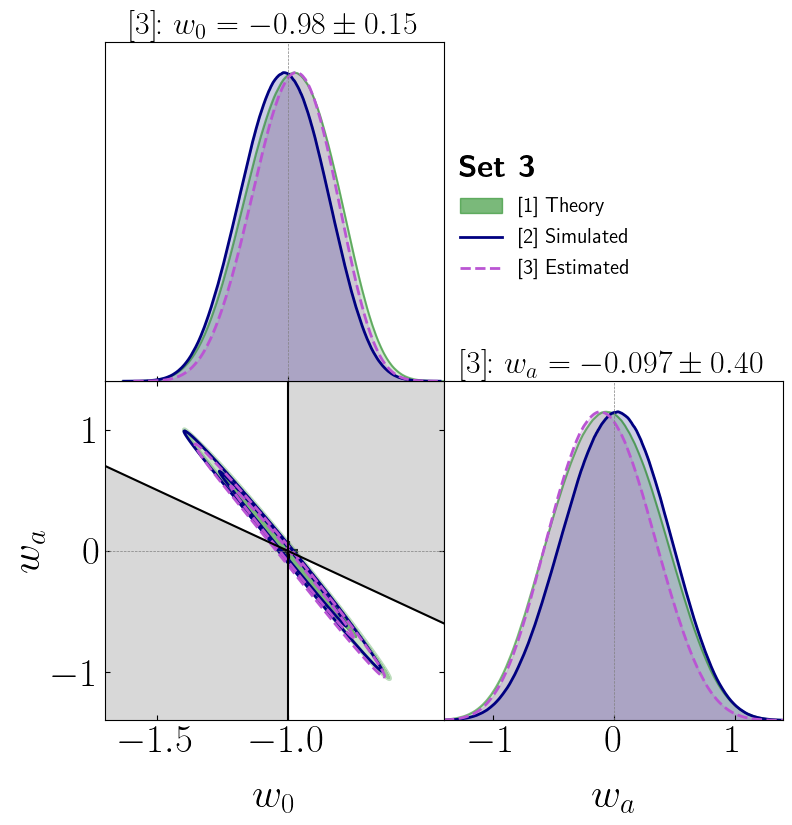

In [206]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [207]:
ibin = 4
bunnin_perc = 0.0
smooth_perc = 0.7
####################
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }
###################################################################################################################
# 5k sims | CV model 3 |TF estimator=HUBER
burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()    
###################################################################################################################
## OLD [NEED 2run new]
#filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_bin{}__newcov__hi_error_{}_simulated.h5".format(ibin,'100')
#burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_simulated.h5".format(ibin, 3)
print( filename_cl_h5 )
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_sim = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
)      
###################################################################################################################
#burnin=100
filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_theory.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_thr = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_thr = chi2.min()    


Backend loaded. Initial number of steps: 5995 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_4bin__COVmodel3__hi_error_100__500sims_estimated.h5
/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_4bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 1755  | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_4bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 3840  | /data/AMARINS/EXTERNAL/DESKTOP/outputs/emcee_cx_cpl_4bin__COVmodel3__hi_error_100__500sims_theory.h5


/data/AMARINS/LSSxHI-CODES/images/2D_cross_set4_4paper.png


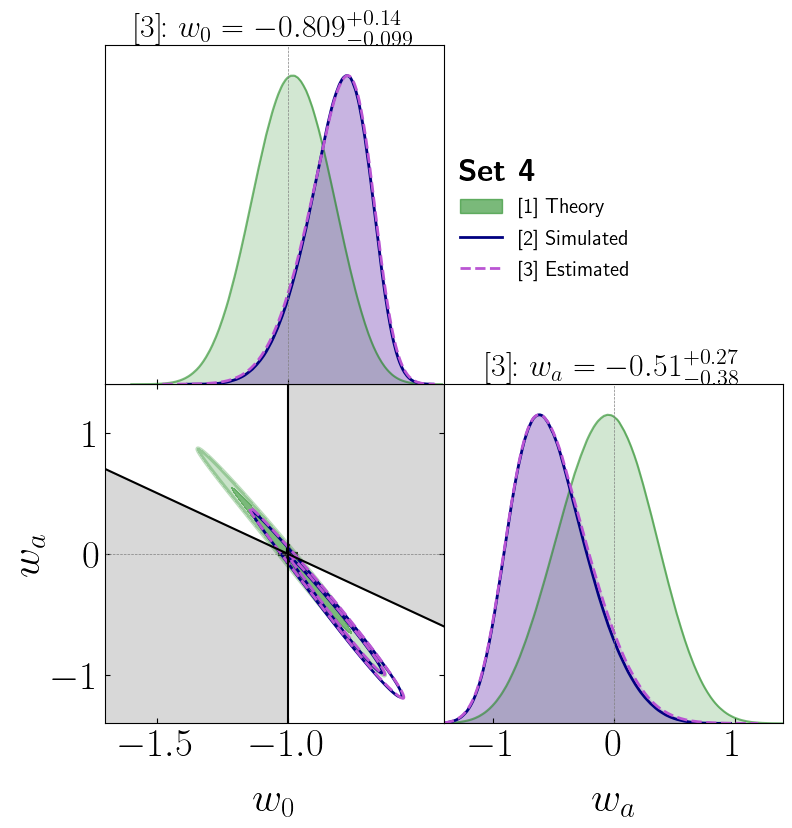

In [208]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [209]:
ibin = 5
bunnin_perc = 0.0
smooth_perc = 0.7
####################
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }
###################################################################################################################
# 5k sims | CV model 3 |TF estimator=HUBER
burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()    
###################################################################################################################
## OLD [NEED 2run new]
#filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_bin{}__newcov__hi_error_{}_simulated.h5".format(ibin,'100')
#burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_simulated.h5".format(ibin, 3)
print( filename_cl_h5 )
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_sim = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
)      
###################################################################################################################
#burnin=100
filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_theory.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_thr = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_thr = chi2.min()    


Backend loaded. Initial number of steps: 4959 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_5bin__COVmodel3__hi_error_100__500sims_estimated.h5
/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_5bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 3258  | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_5bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 5217  | /data/AMARINS/EXTERNAL/DESKTOP/outputs/emcee_cx_cpl_5bin__COVmodel3__hi_error_100__500sims_theory.h5


/data/AMARINS/LSSxHI-CODES/images/2D_cross_set5_4paper.png


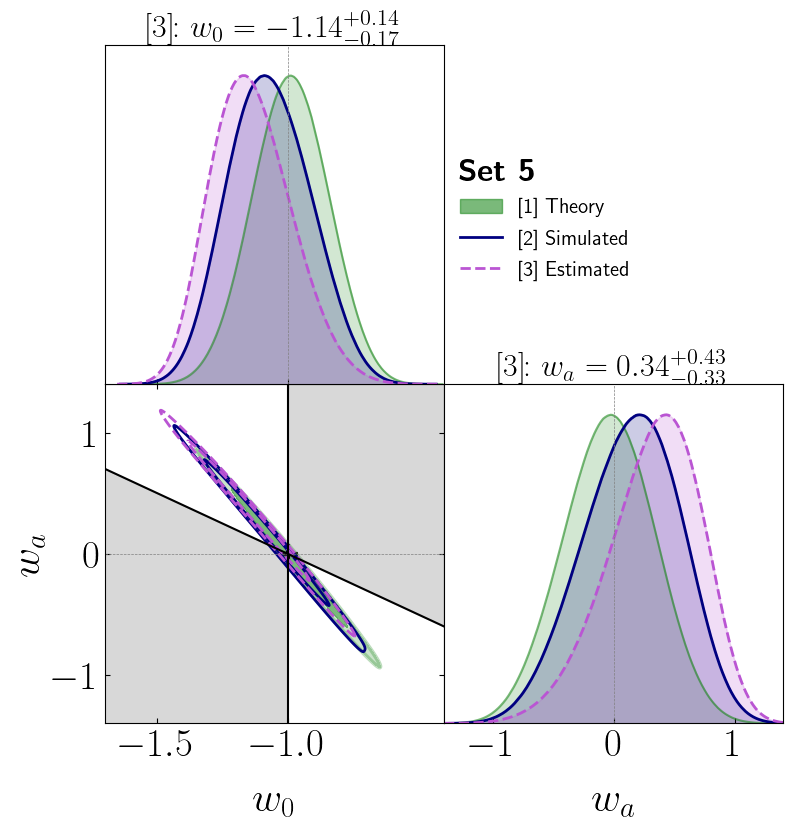

In [210]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [211]:
ibin = 6
bunnin_perc = 0.0
smooth_perc = 0.7
####################
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }
###################################################################################################################
# 5k sims | CV model 3 |TF estimator=HUBER
burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()    
###################################################################################################################
## OLD [NEED 2run new]
#filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_bin{}__newcov__hi_error_{}_simulated.h5".format(ibin,'100')
try:
    #burnin=300
    filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_simulated.h5".format(ibin, 3)
    print( filename_cl_h5 )
    sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
    print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_sim = MCSamples(
            samples=samples_with_chi2,
            names=params,
            labels=labels,
            ignore_rows=bunnin_perc,
            settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )      
except:
    pass
###################################################################################################################
#burnin=100
filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_theory.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_thr = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_thr = chi2.min()    


Backend loaded. Initial number of steps: 6290 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_6bin__COVmodel3__hi_error_100__500sims_estimated.h5
/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_6bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 4103  | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_6bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 6557  | /data/AMARINS/EXTERNAL/DESKTOP/outputs/emcee_cx_cpl_6bin__COVmodel3__hi_error_100__500sims_theory.h5


/data/AMARINS/LSSxHI-CODES/images/2D_cross_set6_4paper.png


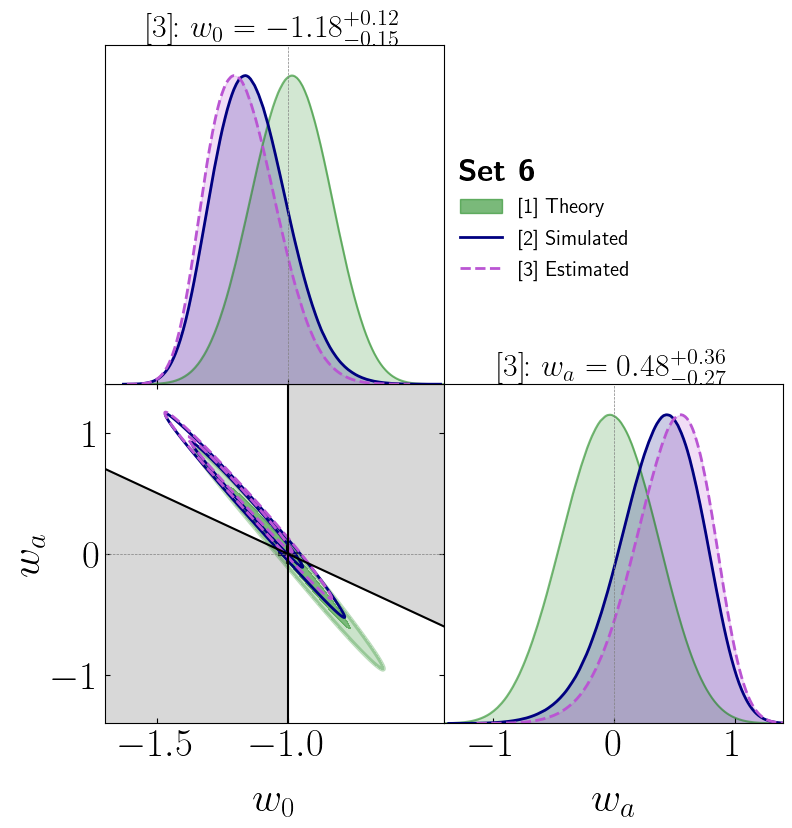

In [212]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [213]:
ibin = 7
bunnin_perc = 0.0
smooth_perc = 0.7
####################
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }
###################################################################################################################
# 5k sims | CV model 3 |TF estimator=HUBER
burnin=300
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()    
###################################################################################################################
## OLD [NEED 2run new]
#filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_bin{}__newcov__hi_error_{}_simulated.h5".format(ibin,'100')
if 1:
    #burnin=300
    filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_simulated.h5".format(ibin, 3)
    print( filename_cl_h5 )
    sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
    print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_sim = MCSamples(
            samples=samples_with_chi2,
            names=params,
            labels=labels,
            ignore_rows=bunnin_perc,
            settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )   
###################################################################################################################
#burnin=100
filename_cl_h5 = PATH['desktop']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_theory.h5".format(ibin, 3)
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}  | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_thr = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_thr = chi2.min()    


Backend loaded. Initial number of steps: 4253 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_7bin__COVmodel3__hi_error_100__500sims_estimated.h5
/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_7bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 1687  | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_7bin__COVmodel3__hi_error_100__500sims_simulated.h5
Backend loaded. Initial number of steps: 3659  | /data/AMARINS/EXTERNAL/DESKTOP/outputs/emcee_cx_cpl_7bin__COVmodel3__hi_error_100__500sims_theory.h5


/data/AMARINS/LSSxHI-CODES/images/2D_cross_set7_4paper.png


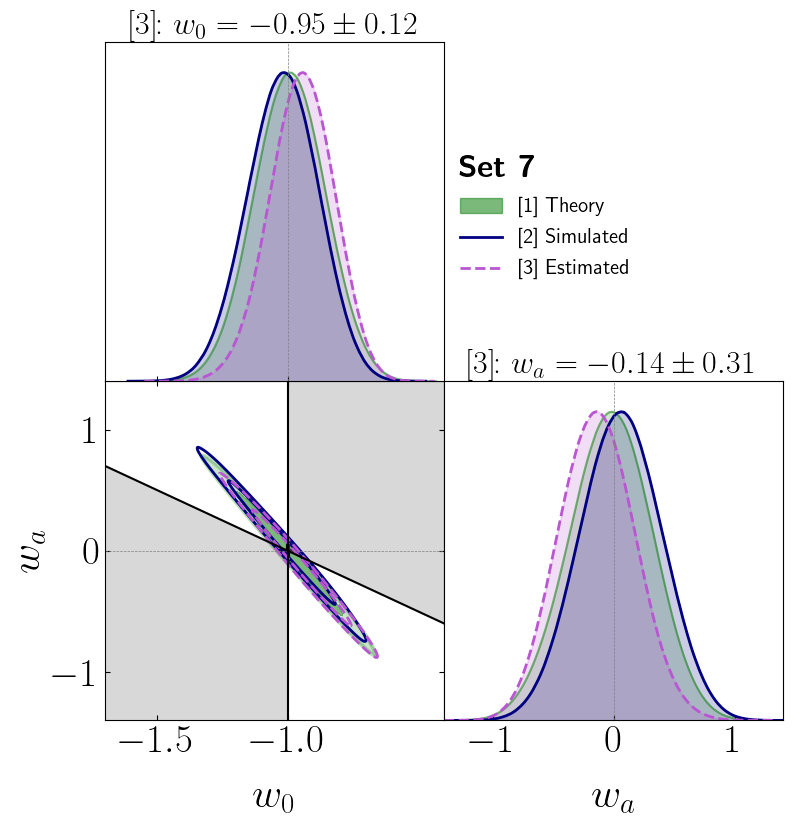

In [214]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'dashed',                                 
                ],    
    contour_lws=[1.5,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': True , 'alpha': 0.6, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 1.0, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid'  , 'lw':1.0, 'alpha': 0.6, 'color':colors[0]},
               {'ls':'solid'  , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'dashed' , 'lw':3.0, 'alpha': 1.0, 'color':colors[2]},               
              ],
    legend_loc=(0.57, 0.65) ,  
    legend_labels=[ 
                   '[1] Theory',         
                   '[2] Simulated',    
                   '[3] Estimated',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)

##########################
ax = gdplot.subplots[1, 0]
ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black')
ax.axvline(x=-1, c='black')
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
ax = gdplot.subplots[1, 1]
ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [0,1,2] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ ["+isamp+"]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", ibin, "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [5]:
burnin=300
#####
filename_cl_h5 = PATH['laptop']+"emcee_cx_cpl_ALLbins__COVmodel{}__hi_error_100__500sims_{}.h5".format(3, 'estimated__huber')
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_est= MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=0.0,
        settings={'smooth_scale_1D': 0.7, 'smooth_scale_2D': 0.7}
)      
##############################
burnin=300
filename_cl_h5 = PATH['laptop']+"emcee_cx_cpl_ALLbins__COVmodel{}__hi_error_100__500sims_{}.h5".format(3, 'simulated')
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_sim= MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=0.0,
        settings={'smooth_scale_1D': 0.7, 'smooth_scale_2D': 0.7}
)      
##############################
burnin=100
filename_cl_h5 = PATH['laptop']+"emcee_cx_cpl_ALLbins__COVmodel{}__hi_error_100__500sims_{}.h5".format(3, 'theory')
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_thr= MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=0.0,
        settings={'smooth_scale_1D': 0.7, 'smooth_scale_2D': 0.7}
)      


Backend loaded. Initial number of steps: 3486
Backend loaded. Initial number of steps: 3472
Backend loaded. Initial number of steps: 3358


/data/AMARINS/LSSxHI-CODES/images/2D_cross_setCombined_4paper.pdf


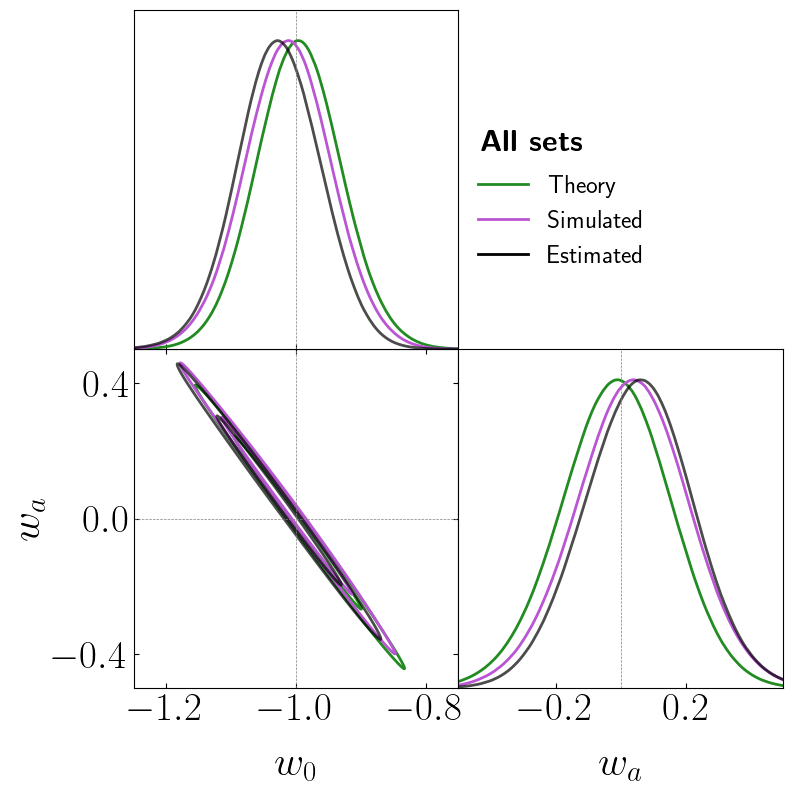

In [11]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 18
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','mediumorchid','black','navy','purple','dodgerblue','crimson','darkorange'
              ]
all_samples = [ samples_thr,
                samples_sim,               
                samples_est,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[False,
            False,    
            False,                
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',
                'solid',                 
                'solid',                                 
                ],    
    contour_lws=[2.0,
                 2.0,
                 2.0,                 
                 ],          
    contour_colors=[
                    colors[0], 
                    colors[1],        
                    colors[2],
                   ], 
    contour_args=[
        {'filled': False, 'alpha': 1.0, 'color': colors[0]},
        {'filled': False, 'alpha': 1.0, 'color': colors[1]},
        {'filled': False, 'alpha': 0.7, 'color': colors[2]},        
    ],    
    line_args=[
               {'ls':'solid' , 'lw':3.0, 'alpha': 1.0, 'color':colors[0]},
               {'ls':'solid' , 'lw':3.0, 'alpha': 1.0, 'color':colors[1]},       
               {'ls':'solid' , 'lw':3.0, 'alpha': 0.7, 'color':colors[2]},               
              ],
    legend_loc=(0.59, 0.65) ,  
    legend_labels=[ 
                   'Theory',         
                   'Simulated',    
                   'Estimated '#+r'$[\star]$',            
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.25,-0.75),
             'wa':(-0.50,+0.50),
                  }
)

##########################
if 0:
    ax = gdplot.subplots[1, 0]
    ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
    x = np.arange(-2,2, 0.0001)
    y1=-1-x
    ax.plot(   x,y1, c='black')
    ax.axvline(x=-1, c='black')
    #upper
    w = (x>=-1)
    x0 = x[w]
    y1 = -1-x0
    y2 = 2
    ax.fill_between(x0, y1, y2, #where=(x > 0), 
                    interpolate=True,
                    color='grey', alpha=0.3)
    #bottom
    w = (x<=-1)
    x0 = x[w]
    y1 = -2
    y2 = -1-x0
    ax.fill_between(x0, y1, y2, #where=(x > 0), 
                    interpolate=True,
                    color='grey', alpha=0.3)
    ax = gdplot.subplots[1, 1]
###########################################################
w0_ticks = [-1.2, -1.0, -0.8]
ax = gdplot.subplots[0, 0]
ax.xaxis.set_major_locator(FixedLocator(w0_ticks))
ax = gdplot.subplots[1, 0]
ax.xaxis.set_major_locator(FixedLocator(w0_ticks))    
###########################################################
ax = gdplot.subplots[1, 1]
target_indices = [] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.2)
###########################################################
ax.text(x=-0.43, y=1.74, s=r'$\textbf{All sets}$', 
            fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 22})
#Manually add the bestfit titles
isamp = 2
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
if 0:
    for i, param_name in enumerate(params[:-1]):
        ax = gdplot.subplots[i, i]
        title_string = r"$ [\star]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
        #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
        ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.pdf".format( '2D',"cross", 'Combined', "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [8]:

ibin = 7
bunnin_perc = 0.0
smooth_perc = 0.7
####################
PATH = {'desktop':'/data/AMARINS/EXTERNAL/DESKTOP/outputs/',
        'laptop' :'/data/AMARINS/EXTERNAL/LAPTOP1/outputs/output/',
        'cosmo1' :'/data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/'
       }
###################################################################################################################
burnin=300;ibin=1
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est_1 = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()  

###################################################################################################################
burnin=300;ibin=2
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est_2 = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()  

###################################################################################################################
burnin=300;ibin=3
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est_3 = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()  

###################################################################################################################
burnin=300;ibin=4
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est_4 = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()      

###################################################################################################################
burnin=300;ibin=5
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est_5 = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()     

###################################################################################################################
burnin=300;ibin=6
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est_6 = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()      

###################################################################################################################
burnin=300;ibin=7
filename_cl_h5 = PATH['cosmo1']+"emcee_cx_cpl_{}bin__COVmodel{}__hi_error_100__500sims_estimated.h5".format(ibin, 3)
sampler = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler.iteration} | {filename_cl_h5}")
if 1:
    #burnin =300
    ##################
    chain  = sampler.get_chain(   discard=burnin, thin=10, flat=False)
    lnprob = sampler.get_log_prob(discard=burnin, thin=10, flat=False)
    #################
    chi2              = -2 * lnprob.flatten()
    samples_flat      = chain.reshape(-1, chain.shape[-1])  
    samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
    params=['w0','wa','chi2']
    labels=[r'w_0',r'w_a',r'\chi^2']
    samples_est_7 = MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=bunnin_perc,
        settings={'smooth_scale_1D': smooth_perc, 'smooth_scale_2D': smooth_perc}
    )        
    chi2_min_est = chi2.min()      

###################################################################################################################
burnin=300
#####
filename_cl_h5 = PATH['laptop']+"emcee_cx_cpl_ALLbins__COVmodel{}__hi_error_100__500sims_{}.h5".format(3, 'estimated__huber')
sampler1 = emcee.backends.HDFBackend(filename_cl_h5)
print(f"Backend loaded. Initial number of steps: {sampler1.iteration}")
##################
chain  = sampler1.get_chain(   discard=burnin, thin=10, flat=False)
lnprob = sampler1.get_log_prob(discard=burnin, thin=10, flat=False)
#################
chi2              = -2 * lnprob.flatten()
samples_flat      = chain.reshape(-1, chain.shape[-1])  
samples_with_chi2 = np.hstack([samples_flat, chi2.reshape(-1, 1)])
params=['w0','wa','chi2']
labels=[r'w_0',r'w_a',r'\chi^2']
samples_est_all= MCSamples(
        samples=samples_with_chi2,
        names=params,
        labels=labels,
        ignore_rows=0.0,
        settings={'smooth_scale_1D': 0.7, 'smooth_scale_2D': 0.7}
)        

Backend loaded. Initial number of steps: 5020 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_1bin__COVmodel3__hi_error_100__500sims_estimated.h5
Backend loaded. Initial number of steps: 3950 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_2bin__COVmodel3__hi_error_100__500sims_estimated.h5
Backend loaded. Initial number of steps: 3751 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_3bin__COVmodel3__hi_error_100__500sims_estimated.h5
Backend loaded. Initial number of steps: 5995 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_4bin__COVmodel3__hi_error_100__500sims_estimated.h5
Backend loaded. Initial number of steps: 4959 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_5bin__COVmodel3__hi_error_100__500sims_estimated.h5
Backend loaded. Initial number of steps: 6290 | /data/AMARINS/LSSxHI-CODES/notebooks/forecast/output/emcee_cx_cpl_6bin__COVmodel3__hi_error_100__500sims_estimated.h5
Back

In [156]:
cmap = plt.get_cmap("tab10", 9+1)

/data/AMARINS/LSSxHI-CODES/images/2D_cross_setALLs_4paper.png


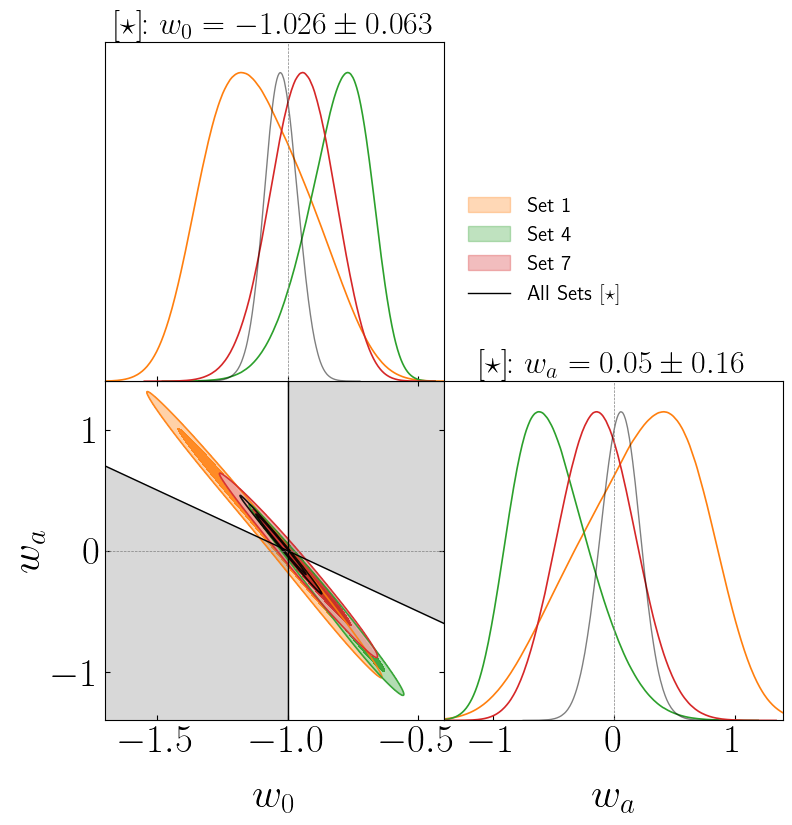

In [157]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 15
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
#gdplot.settings.legend_frame      = False       
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['forestgreen','navy','mediumorchid','purple','dodgerblue','crimson','black','darkorange'
              ]
all_samples = [ samples_est_1, #samples_est_2, samples_est_3,
                samples_est_4, #samples_est_5, samples_est_6,
                samples_est_7, samples_est_all,
              ]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[True, # True,  True,
            True, #True, True,
            True, False
           ],
    contour_levels=[0.68],#, 0.95],
    #scatter_param='chi2',  # Color points by chi²
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls=['solid',#'solid', 'solid',
                'solid',#'solid', 'solid',
                'solid', 'solid'
                ],    
    contour_lws=[1.2,#1.2,1.2,
                 1.2,#1.2,1.2,
                 1.2,1.0],          
    contour_colors=[
                    cmap(1),#cmap(1),cmap(2),
                    cmap(2),#cmap(4),cmap(5),
                    cmap(3), 'black'
                   ], 
    contour_args=[
        #{'filled': True, 'alpha': 0.3, 'color': cmap(0)},
        {'filled': True, 'alpha': 0.3, 'color': cmap(1)},
        {'filled': True, 'alpha': 0.3, 'color': cmap(2)},
        {'filled': True, 'alpha': 0.3, 'color': cmap(3)},
        #{'filled': True, 'alpha': 0.3, 'color': cmap(4)},
        #{'filled': True, 'alpha': 0.3, 'color': cmap(5)},
        #{'filled': True, 'alpha': 0.3, 'color': cmap(6)},
        {'filled': True, 'alpha': 0.3, 'color': 'black'},        
    ],    
    line_args=[
               #{'ls':'solid' , 'lw':1.0, 'alpha': 1.0, 'color': cmap(0)},
               {'ls':'solid' , 'lw':1.0, 'alpha': 1.0, 'color': cmap(1)},
               {'ls':'solid' , 'lw':1.0, 'alpha': 1.0, 'color': cmap(2)},
               {'ls':'solid' , 'lw':1.0, 'alpha': 1.0, 'color': cmap(3)},
               #{'ls':'solid' , 'lw':1.0, 'alpha': 1.0, 'color': cmap(4)},
               #{'ls':'solid' , 'lw':1.0, 'alpha': 1.0, 'color': cmap(5)},
               #{'ls':'solid' , 'lw':1.0, 'alpha': 1.0, 'color': cmap(6)},
               {'ls':'dashed', 'lw':1.0, 'alpha': 0.5, 'color': 'black'},        
              ],
    legend_loc=(0.58, 0.62) ,  
    legend_labels=[ 
                   'Set 1',
                   #'Set 2',
                   #'Set 3',
                   'Set 4',
                   #'Set 5',
                   #'Set 6',
                   'Set 7', 
                   'All Sets '+r'$[\star]$',         
                   ],
    markers={"w0": -1, 'wa':0, },
    param_limits={
             'w0':(-1.7,-0.4),
             'wa':(-1.4,+1.4),                
                  }
)
##########################
ax = gdplot.subplots[1, 0]
for coll in ax.collections:
    try:
        coll.set_linewidth(1.2)
        coll.set_alpha(0.9)
    except:
        pass
##########################
ax = gdplot.subplots[1, 0]
#ax.scatter(-1,0, color='black', marker='+', s=200, lw=3)  # red star
x = np.arange(-2,2, 0.0001)
y1=-1-x
ax.plot(   x,y1, c='black', lw=1)
ax.axvline(x=-1, c='black', lw=1)
#upper
w = (x>=-1)
x0 = x[w]
y1 = -1-x0
y2 = 2
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#bottom
w = (x<=-1)
x0 = x[w]
y1 = -2
y2 = -1-x0
ax.fill_between(x0, y1, y2, #where=(x > 0), 
                interpolate=True,
                color='grey', alpha=0.3)
#ax = gdplot.subplots[1, 1]
#ax.text(x=-1.28, y=1.76, s=r'$\textbf{Set $'+r'${}$'.format(ibin)+r"$}$", 
#        fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 23})
###########################
ax = gdplot.subplots[1, 1]
target_indices = [] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.15)
###########################
#Manually add the bestfit titles
isamp = 3
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
for i, param_name in enumerate(params[:-1]):
    ax = gdplot.subplots[i, i]
    title_string = r"$ [\star]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
    #title_string = f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$".replace(" =", "^{["+isamp+"]} =")
    ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
###########################################################
w0_ticks = [-1.5, -1.0, -0.5]
ax = gdplot.subplots[0, 0]
ax.xaxis.set_major_locator(FixedLocator(w0_ticks))
ax = gdplot.subplots[1, 0]
ax.xaxis.set_major_locator(FixedLocator(w0_ticks))    
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}.png".format( '2D',"cross", 'ALLs', "4paper" )
#plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()

In [208]:
cmap = plt.get_cmap("CMRmap", 6+1)
#cmap = plt.get_cmap("ocean", 7+1)
cmap = plt.get_cmap("tab10", 3+1)

/data/AMARINS/LSSxHI-CODES/images/2D_cross_setALLs_4paper__V3.pdf


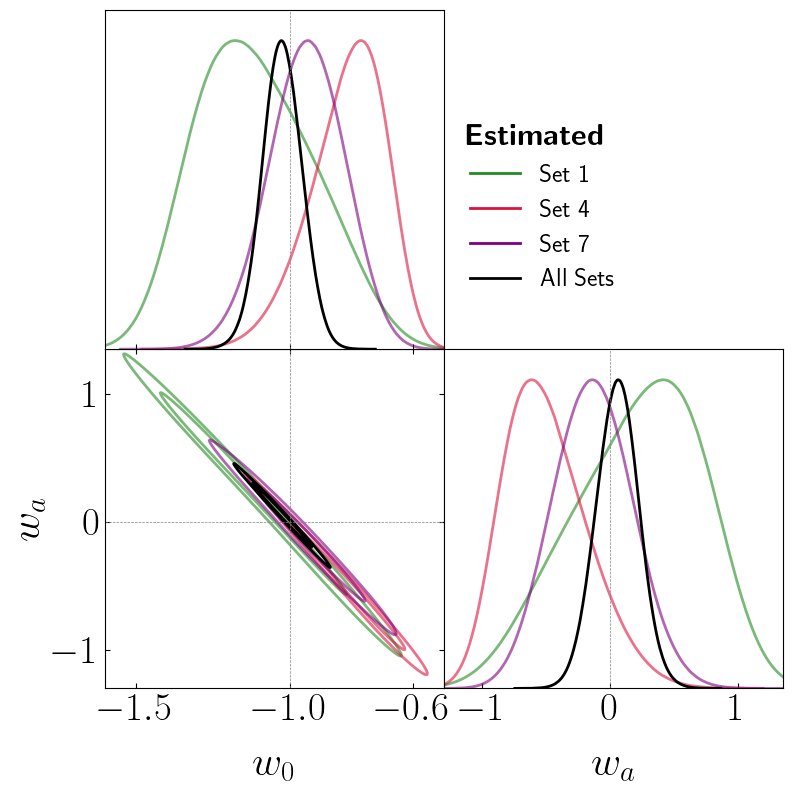

In [13]:
###############################################################################
from getdist import plots
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
##
gdplot = plots.get_subplot_plotter(subplot_size=12, width_inch=14)
gdplot.settings.axes_fontsize = 28
gdplot.settings.lab_fontsize = 30
gdplot.settings.legend_fontsize = 18
gdplot.settings.title_limit_fontsize = 23 #<---legendas dos bestfits
gdplot.settings.alpha_filled_add = 0.6
gdplot.settings.alpha_filled_add = 0.5
gdplot.settings.scatter_size = 20
gdplot.settings.legend_loc        = 'lower right'
gdplot.settings.num_plot_contours = 2   
gdplot.settings.figure_legend_frame = False 
gdplot.settings.figure_legend_loc = 'upper center'
colors      = ['navy','mediumorchid','forestgreen','black']
colors      = ['forestgreen','crimson','purple','black','darkorange']
#colors      = [cmap(1),cmap(2),cmap(3),'black']
#colors      = [cmap(0),cmap(3),cmap(5),'black']
all_samples = [ samples_est_1, samples_est_4, samples_est_7, samples_est_all]
gdplot.triangle_plot(
    all_samples,
    params=params[:-1],  # Parameters to plot (exclude chi² itself)
    filled=[False,False,False, False],
    contour_levels=[0.68],#, 0.95],
    title_limit=0,#1,          # 1:Show 1-sigma limits in titles; 0:dont show anything
    contour_ls =['solid','solid', 'solid','solid'],    
    contour_lws=[2,2,2,2.0],          
    contour_colors=[colors[0],colors[1],colors[2],colors[3]], 
    contour_args=[
        {'filled': True, 'alpha': 0.6, 'color': colors[0]},
        {'filled': True, 'alpha': 0.6, 'color': colors[1]},
        {'filled': True, 'alpha': 0.6, 'color': colors[2]},
        {'filled': True, 'alpha': 1.0, 'color': colors[3]},        
    ],    
    line_args=[
               {'ls':'solid' , 'lw':1.5, 'alpha': 0.6, 'color': colors[0]},
               {'ls':'solid' , 'lw':1.5, 'alpha': 0.6, 'color': colors[1]},
               {'ls':'solid' , 'lw':1.5, 'alpha': 0.6, 'color': colors[2]},
               {'ls':'dashed', 'lw':2.0, 'alpha': 1.0, 'color': colors[3]},        
              ],
    legend_loc=(0.58, 0.62) ,  
    legend_labels=['Set 1','Set 4','Set 7', 
                 'All Sets '#+r'$[\star]$'
                  ],
    markers={"w0": -1, 'wa':0, },
    param_limits={'w0':(-1.6,-0.5),
                  'wa':(-1.3,+1.35)}
)
###########################
ax = gdplot.subplots[1, 1]
target_indices = [] 
num_params = len(params[:-1])
for i in range(num_params):
    ax = gdplot.subplots[i, i]
    for line_index, line in enumerate(ax.get_lines()):
        if line_index in target_indices:
            x, y = line.get_data()
            ax.fill_between(x, y, color=line.get_color(), alpha=0.15)
###########################
isamp = 3
icolor = colors[isamp]
sample_for_titles = all_samples[isamp]
isamp = str(isamp+1)
if 0:
    for i, param_name in enumerate(params[:-1]):
        ax = gdplot.subplots[i, i]
        title_string = r"$ [\star]\!\!:$ "+f"${sample_for_titles.getInlineLatex(param_name, limit=1)}$"
        ax.set_title(title_string, fontsize=gdplot.settings.title_limit_fontsize)#, color=icolor)  
ax.text(x=-1.13, y=1.76, s=r'$\textbf{Estimated}$', 
            fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 22})
###########################################################
w0_ticks = [-1.5, -1.0, -0.6]
ax = gdplot.subplots[0, 0]
ax.xaxis.set_major_locator(FixedLocator(w0_ticks))
ax = gdplot.subplots[1, 0]
ax.xaxis.set_major_locator(FixedLocator(w0_ticks))    
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}_{}_set{}_{}__V3.pdf".format( '2D',"cross", 'ALLs', "4paper" )
plt.savefig(pathname, dpi=100, bbox_inches='tight');
print(pathname)
###########################################################
plt.show()